In [1]:
%env TF_CPP_MIN_LOG_LEVEL=2

env: TF_CPP_MIN_LOG_LEVEL=2


In [2]:
import tensorflow as tf

print("CUDA Built:", tf.test.is_built_with_cuda())
print("Physical GPUs:", tf.config.list_physical_devices('GPU'))

CUDA Built: True
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import numpy as np
import tensorflow_datasets as tfds

train_ds,test_ds,validation_ds = tfds.load("gigaword", split=['train', 'test', 'validation'], as_supervised=True)

#Because the dataset is too large, we will slice it for training and testing. We are using 80/20 split for training and testing respectively.
train_ds = train_ds.take(2000)
test_ds = test_ds.take(500)
validation_ds = validation_ds.take(500)

#Coverting the dataset into numpy arrays for training and testing.
X_train = np.array([x.numpy() for x, y in train_ds])
y_train = np.array([y.numpy() for x, y in train_ds])

X_test = np.array([x.numpy() for x, y in test_ds])
y_test = np.array([y.numpy() for x, y in test_ds])

X_validation = np.array([x.numpy() for x, y in validation_ds])
y_validation = np.array([y.numpy() for x, y in validation_ds])

#To know the shape of the dataset.
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape, X_validation.shape, y_validation.shape)

(2000,) (2000,) (500,) (500,) (500,) (500,)


In [4]:
print(y_train[0], X_train[0], sep="\n")

b'fair trade commission investigating consumer price hike'
b'officials of the cabinet-level fair trade commission -lrb- ftc -rrb- said friday that they have formed an ad hoc group to investigate whether there is any manipulation of commodity prices by traders in local market .'


In [5]:
# The data have the b"" prefix, we will remove it.
X_train, X_test, X_validation, y_train, y_test, y_validation = [
    np.array([x.decode('utf-8') for x in split])
    for split in (X_train, X_test, X_validation, y_train, y_test, y_validation)
]

# let see the data again.
print(y_train[0], X_train[0], sep="\n")

fair trade commission investigating consumer price hike
officials of the cabinet-level fair trade commission -lrb- ftc -rrb- said friday that they have formed an ad hoc group to investigate whether there is any manipulation of commodity prices by traders in local market .


The data is now ready for preprocessing. We will use the Tokenizer class from Keras to convert the text data into sequences of integers. This will allow us to feed the data into a neural network model for training.

In [6]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing import sequence

NUM_WORDS = 10000       # Number of most frequent words to use
INPUT_SEQ_LEN = 60      # Maximum article length
TARGET_SEQ_LEN = 50     # Maximum summary length

def preprocess_data(X_train, y_train, X_test, y_test, X_validation, y_validation):
    tokenizer_x = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
    tokenizer_x.fit_on_texts(X_train)

    X_train_pad, X_test_pad, X_validation_pad = [
        sequence.pad_sequences(
            tokenizer_x.texts_to_sequences(split),
            maxlen=INPUT_SEQ_LEN,
            padding="post",
            truncating="post",
        )
        for split in (X_train, X_test, X_validation)
    ]

    # Start and end tokens
    startseq = "<startseq>"
    endseq = "<endseq>"
    y_train, y_test, y_validation = [
        [f"{startseq} {text} {endseq}" for text in split]
        for split in (y_train, y_test, y_validation)]

    tokenizer_y = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
    tokenizer_y.fit_on_texts(y_train)

    y_train_pad, y_test_pad, y_validation_pad = [
        sequence.pad_sequences(
            [
                seq[:TARGET_SEQ_LEN - 1] + seq[-1:] if len(seq) > TARGET_SEQ_LEN else seq
                for seq in tokenizer_y.texts_to_sequences(split)
            ],
            maxlen=TARGET_SEQ_LEN,
            padding="post",
            truncating="post",
        )
        for split in (y_train, y_test, y_validation)
    ]

    return X_train_pad, y_train_pad, X_test_pad, y_test_pad, X_validation_pad, y_validation_pad, tokenizer_y

In [48]:
def compile_and_fit_model(model, X_train, y_train, X_valid, y_valid,
                          epochs, batch_size, verbose):

    valid_mask = (y_valid != 0).astype("float32")
    train_mask = (y_train != 0).astype("float32")


    model.compile(loss="sparse_categorical_crossentropy",
                  optimizer="adam",
                  weighted_metrics=["acc"])

    history = model.fit(X_train,
                        y_train,
                        sample_weight=train_mask,
                        epochs=epochs,
                        batch_size=batch_size,
                        verbose=verbose,
                        validation_data=(X_valid, y_valid, valid_mask))

    return history

In [8]:
def history_final_values(history):
    return {k: round(v[-1], 4) for k, v in history.history.items()}

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_history(history):
    df = pd.DataFrame(history.history)
    df.index = df.index + 1
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    df.plot(y=["loss", "val_loss"], grid=True, ax=axs[0])
    df.plot(y=["acc", "val_acc"], grid=True, ax=axs[1])
    plt.tight_layout()

In [10]:
final_values = {}

In [52]:
# Teacher forcing and seq2seq
X_train_pad, y_train_pad, X_test_pad, y_test_pad, X_validation_pad, y_validation_pad, tokenizer_y = preprocess_data(X_train, y_train, X_test, y_test, X_validation, y_validation)
#Shifting the target sequence by one time step to the right, so that the decoder can learn to predict the next token in the sequence given the previous tokens.
decoder_input_train = y_train_pad[:, :-1]
decoder_target_train = y_train_pad[:, 1:]

decoder_input_val = y_validation_pad[:, :-1]
decoder_target_val = y_validation_pad[:, 1:]

#ENCODER
encoder_input = keras.Input(shape=(INPUT_SEQ_LEN,),dtype="int32") #An input for the article tokens.

encoder_embedding = layers.Embedding(NUM_WORDS, 64,mask_zero=True)(encoder_input)
sequence_layer  = layers.Bidirectional(layers.LSTM(64,return_state=True))
result = sequence_layer(encoder_embedding)

encoder_output, forward_h, forward_c, backward_h, backward_c = result

#join the forward and backward hidden states
state_h = layers.Concatenate()([forward_h, backward_h]) # combine both hidden and cell states
state_c = layers.Concatenate()([forward_c, backward_c])
encoder_states = [state_h, state_c] # make it a list to pass to the decoder

#DECODER
#Type of rnn that returns the full sequence of outputs for each input sequence, as well as the final hidden and cell states.
decoder_input = keras.Input(shape=(TARGET_SEQ_LEN-1,),dtype="int32")
decoder_embedding = layers.Embedding(NUM_WORDS, 64)(decoder_input)
decoder_lstm = layers.LSTM(128, return_sequences=True, return_state=True)
decoder_output, _, _ = decoder_lstm(decoder_embedding, initial_state=encoder_states)
decoder_dense = layers.TimeDistributed(layers.Dense(NUM_WORDS, activation="softmax"))
decoder_output = decoder_dense(decoder_output) #predicts the word probabilities for each time step in the output sequence.

model = keras.Model([encoder_input, decoder_input], decoder_output)

history = compile_and_fit_model(
    model,
    [X_train_pad, decoder_input_train],
    decoder_target_train,
    [X_validation_pad, decoder_input_val],
    decoder_target_val,
    epochs=50,
    batch_size=256,
    verbose=2
)
final_values[model.name] = history_final_values(history)
print(final_values[model.name])


Epoch 1/50
8/8 - 5s - 647ms/step - acc: 0.0811 - loss: 1.7088 - val_acc: 0.1067 - val_loss: 1.7591
Epoch 2/50
8/8 - 2s - 216ms/step - acc: 0.1099 - loss: 1.7019 - val_acc: 0.1067 - val_loss: 1.7358
Epoch 3/50
8/8 - 2s - 201ms/step - acc: 0.1099 - loss: 1.6234 - val_acc: 0.1067 - val_loss: 1.5826
Epoch 4/50
8/8 - 2s - 204ms/step - acc: 0.1099 - loss: 1.4455 - val_acc: 0.1067 - val_loss: 1.4614
Epoch 5/50
8/8 - 2s - 212ms/step - acc: 0.1099 - loss: 1.3329 - val_acc: 0.1067 - val_loss: 1.4380
Epoch 6/50
8/8 - 2s - 208ms/step - acc: 0.1099 - loss: 1.2984 - val_acc: 0.1067 - val_loss: 1.4415
Epoch 7/50
8/8 - 2s - 199ms/step - acc: 0.1099 - loss: 1.2859 - val_acc: 0.1067 - val_loss: 1.4402
Epoch 8/50
8/8 - 2s - 201ms/step - acc: 0.1099 - loss: 1.2802 - val_acc: 0.1067 - val_loss: 1.4462
Epoch 9/50
8/8 - 2s - 204ms/step - acc: 0.1099 - loss: 1.2728 - val_acc: 0.1067 - val_loss: 1.4507
Epoch 10/50
8/8 - 2s - 200ms/step - acc: 0.1099 - loss: 1.2678 - val_acc: 0.1067 - val_loss: 1.4541
Epoch 11/

In [49]:
history = compile_and_fit_model(
    model,
    [X_train_pad[:10], decoder_input_train[:10]],
    decoder_target_train[:10],
    [X_validation_pad, decoder_input_val],
    decoder_target_val,
    epochs=50,
    batch_size=2,
    verbose=2
)

Epoch 1/50
5/5 - 5s - 1s/step - acc: 0.1209 - loss: 0.7261 - val_acc: 0.1129 - val_loss: 2.0855
Epoch 2/50
5/5 - 2s - 348ms/step - acc: 0.1538 - loss: 0.7058 - val_acc: 0.1231 - val_loss: 2.1059
Epoch 3/50
5/5 - 2s - 349ms/step - acc: 0.1648 - loss: 0.6989 - val_acc: 0.1231 - val_loss: 2.1225
Epoch 4/50
5/5 - 2s - 351ms/step - acc: 0.1648 - loss: 0.6936 - val_acc: 0.1229 - val_loss: 2.1448
Epoch 5/50
5/5 - 2s - 352ms/step - acc: 0.1648 - loss: 0.6900 - val_acc: 0.1236 - val_loss: 2.1683
Epoch 6/50
5/5 - 2s - 349ms/step - acc: 0.1648 - loss: 0.6855 - val_acc: 0.1227 - val_loss: 2.1900
Epoch 7/50
5/5 - 2s - 353ms/step - acc: 0.1648 - loss: 0.6817 - val_acc: 0.1221 - val_loss: 2.2092
Epoch 8/50
5/5 - 2s - 350ms/step - acc: 0.1648 - loss: 0.6797 - val_acc: 0.1240 - val_loss: 2.2248
Epoch 9/50
5/5 - 2s - 352ms/step - acc: 0.1538 - loss: 0.6762 - val_acc: 0.1251 - val_loss: 2.2436
Epoch 10/50
5/5 - 2s - 351ms/step - acc: 0.1538 - loss: 0.6736 - val_acc: 0.1246 - val_loss: 2.2590
Epoch 11/50


In [15]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 60, 64)    │    640,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 60)        │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 49)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ [(None, 128),     │     66,048 │ embedding_4[0][0… │
│ (Bidirectional)     │ (None, 64),       │            │ not_equal_1[0][0] │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 49, 64)    │    640,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128)       │          0 │ bidirectional_3[… │
│ (Concatenate)       │                   │            │ bidirectional_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 128)       │          0 │ bidirectional_3[… │
│ (Concatenate)       │                   │            │ bidirectional_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_7 (LSTM)       │ [(None, 49, 128), │     98,816 │ embedding_5[0][0… │
│                     │ (None, 128),      │            │ concatenate_2[0]… │
│                     │ (None, 128)]      │            │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_3  │ (None, 49, 10000) │  1,290,000 │ lstm_7[0][0]      │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,204,594 (31.30 MB)

 Trainable params: 2,734,864 (10.43 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,469,730 (20.87 MB)

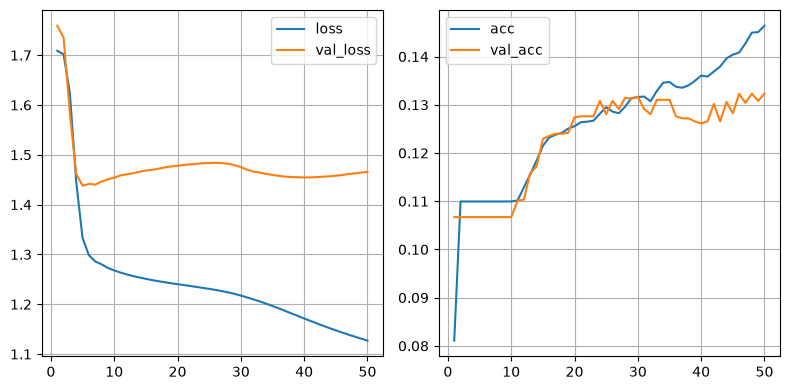

In [53]:
plot_history(history)

In [63]:
y_validation_seq = tokenizer_y.sequences_to_texts(y_validation_pad)
y_pred = model.predict([X_validation_pad, decoder_input_val])

ValueError: Can't convert non-rectangular Python sequence to Tensor.

In [58]:
y_pred_argmax = np.argmax(y_pred, axis=-1)
is_padding = (y_pred_argmax == 0)
print(np.mean(is_padding))

0.0


In [59]:
valid = decoder_target_val != 0
end_id = tokenizer_y.word_index["endseq"]
print(np.mean(y_pred_argmax[valid] == end_id))

0.35552710200597526


In [60]:
print(tokenizer_y.sequences_to_texts(y_pred_argmax))

["u 's to to to in in endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq", "u 's to to to in in in endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq", 'u president to to to in the endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq endseq', "u 's to to the in be endseq endseq endseq e